# 25. 금형온도·계량위치 '수준'이 불량과 관련 있나 → 최종 모델과 합쳐 다시 평가

**기준 (라벨 미사용)**: 최종 모델 학습에 쓴 정상 생산 샷(unlabeled, 9~11월, 0 모드 제거)의 분포
수준 z = (값 − 정상 중앙값) / 정상 IQR → **Run 간 차이를 그대로 담는 절대 수준 지표**
(최종 모델 변수는 '같은 Run 직전 20샷 대비'라 Run 전체 수준 차이가 지워져 있음)

**A. 검토**
- A-1 Run별 수준과 정상 기준 범위(1~99%) 밖 비율
- A-2 (a) R1 정상 vs 다른 Run 정상 / (b) **R1 안에서** 가스 vs R1 정상
  → (a)만 크고 (b)가 작으면: R1이라는 '구간'이 다를 뿐 R1 안에서 가스를 가려 주지는 못함

**B. 결합 모델 (사전 고정)**: `L_level` 수준 점수 단독 / `C_mean` 최종+수준 이상도 평균 / `C_max` 둘 중 큰 값
- **Run별 상위10%**·**R1 내부 AP**는 'R1 전체를 높게 매기는 것'으로는 오르지 않는 지표 → 진짜 가스 구분력
- **R1 정상 경보 비율**: R1 정상 샷이 경보로 얼마나 쏟아지나 (현장 검사 부담)
- RG3에도 같은 방법 적용 → 재현되는지 확인

In [1]:
import os
import pandas as pd
from level_check import (prepare, run_table, diff_tests, plot_levels, evaluate, reference_scores,
                         reference_thresholds, eval_frame1)
pd.set_option('display.width', 250); pd.set_option('display.max_columns', 40)
OUT = './outputs/level_check'
os.makedirs(OUT, exist_ok=True)

D, REF, INFO = {}, {}, {}
for p in ['cn7', 'rg3']:
    D[p], REF[p], INFO[p] = prepare(p)

## A-1. Run별 수준

CN7


,제품,Run,샷,불량,가스,미성형계열,금형온도3 정상 중앙값,금형온도3 불량 중앙값,금형온도3 기준범위 밖 비율,계량위치 정상 중앙값,계량위치 불량 중앙값,계량위치 기준범위 밖 비율
0,cn7,cn7_R1,188,14.0,11.0,3.0,25.00,25.1,0.000,68.84,68.84,0.00
1,cn7,cn7_R2,418,0.0,0.0,0.0,22.80,NaN,0.000,68.49,NaN,0.00
2,cn7,cn7_R3,309,0.0,0.0,0.0,22.40,NaN,0.074,68.59,NaN,0.00
3,cn7,cn7_R4,189,0.0,0.0,0.0,22.90,NaN,0.000,68.49,NaN,0.00
4,cn7,cn7_R5,407,0.0,0.0,0.0,21.70,NaN,0.135,68.25,NaN,0.00
5,cn7,cn7_R6,463,1.0,0.0,1.0,21.35,22.2,0.006,68.34,68.36,0.00
6,cn7,reference(정상 기준),5179,NaN,NaN,NaN,24.70,NaN,0.020,68.50,NaN,0.02


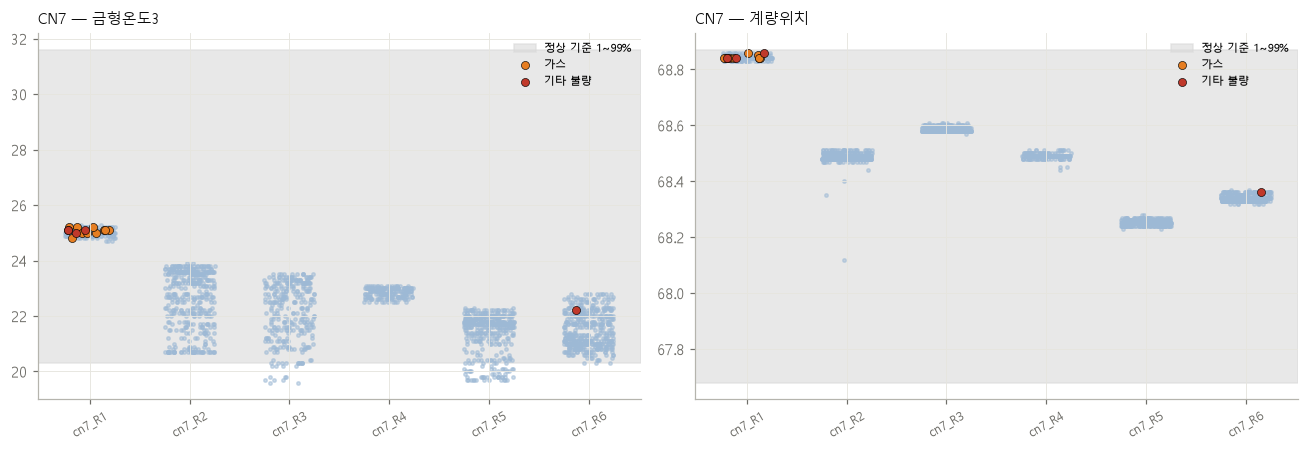

RG3


,제품,Run,샷,불량,가스,미성형계열,금형온도3 정상 중앙값,금형온도3 불량 중앙값,금형온도3 기준범위 밖 비율,계량위치 정상 중앙값,계량위치 불량 중앙값,계량위치 기준범위 밖 비율
0,rg3,rg3_R1,41,0.0,0.0,0.0,21.4,NaN,0.00,53.59,NaN,0.00
1,rg3,rg3_R2,103,5.0,4.0,1.0,21.9,22.00,0.00,53.59,53.58,0.00
2,rg3,rg3_R3,197,10.0,6.0,4.0,22.8,22.60,0.00,53.57,53.57,0.00
3,rg3,rg3_R4,74,4.0,3.0,1.0,21.7,21.60,0.00,53.59,53.59,0.00
4,rg3,rg3_R5,176,6.0,4.0,2.0,23.4,23.35,0.00,53.59,53.59,0.00
5,rg3,rg3_R6,36,7.0,5.0,2.0,22.4,22.40,0.00,53.61,53.61,0.00
6,rg3,reference(정상 기준),4359,NaN,NaN,NaN,21.2,NaN,0.02,53.58,NaN,0.02


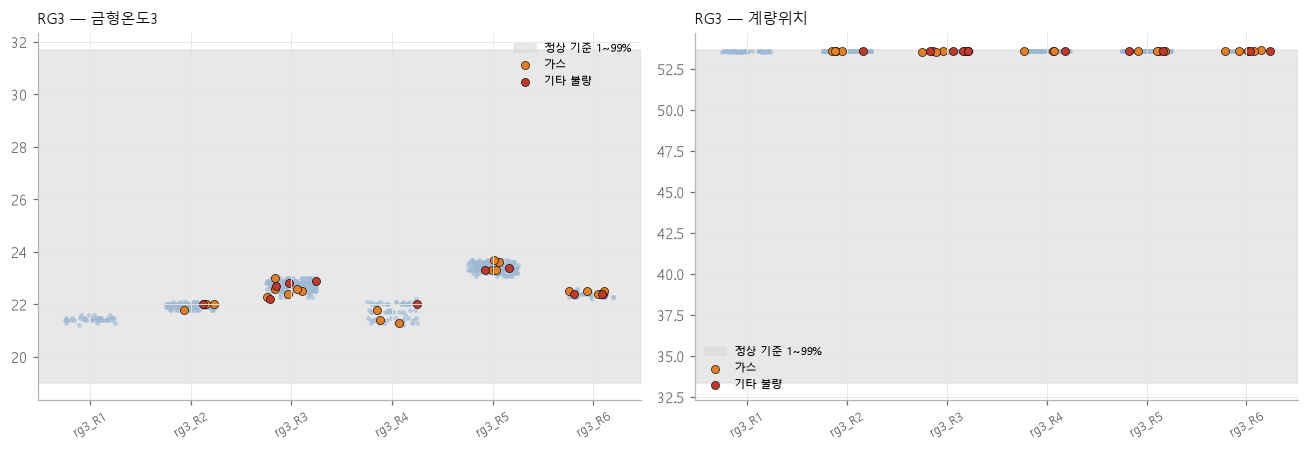

In [2]:
for p in ['cn7', 'rg3']:
    t = run_table(p, D[p], INFO[p]); t.to_csv(f'{OUT}/A1_runs_{p}.csv', index=False, encoding='utf-8-sig')
    print(p.upper()); display(t.round(3))
    plot_levels(p, D[p], INFO[p], save=f'{OUT}/A1_levels_{p}.png')

## A-2. 차이 검정 — (a) Run 간 / (b) 불량이 몰린 Run 안에서

In [3]:
for p, defect in [('cn7', '가스'), ('cn7', '미성형'), ('rg3', '가스'), ('rg3', '미성형')]:
    t = diff_tests(p, D[p], defect=defect)
    if len(t):
        print(p.upper(), defect); display(t.round(3))

CN7 가스


,제품,변수,비교,n(앞),n(뒤),중앙값(앞),중앙값(뒤),Cliff's δ,p
0,cn7,금형온도3,(a) cn7_R1 정상 vs 다른 Run 정상,174,1785,25.000,22.000,1.000,0.000
1,cn7,금형온도3,(b) cn7_R1 안: 가스 vs 정상,11,174,25.100,25.000,0.301,0.077
2,cn7,계량위치,(a) cn7_R1 정상 vs 다른 Run 정상,174,1785,68.840,68.480,1.000,0.000
3,cn7,계량위치,(b) cn7_R1 안: 가스 vs 정상,11,174,68.840,68.840,0.069,0.669
4,cn7,최종 모델 점수(참고),(a) cn7_R1 정상 vs 다른 Run 정상,174,1785,2.796,3.017,-0.129,0.005
5,cn7,최종 모델 점수(참고),(b) cn7_R1 안: 가스 vs 정상,11,174,2.927,2.796,0.122,0.499


CN7 미성형


,제품,변수,비교,n(앞),n(뒤),중앙값(앞),중앙값(뒤),Cliff's δ,p
0,cn7,금형온도3,(a) cn7_R1 정상 vs 다른 Run 정상,174,1785,25.000,22.000,1.000,0.000
1,cn7,금형온도3,(b) cn7_R1 안: 미성형 vs 정상,1,174,25.000,25.000,-0.080,0.891
2,cn7,계량위치,(a) cn7_R1 정상 vs 다른 Run 정상,174,1785,68.840,68.480,1.000,0.000
3,cn7,계량위치,(b) cn7_R1 안: 미성형 vs 정상,1,174,68.840,68.840,-0.086,0.878
4,cn7,최종 모델 점수(참고),(a) cn7_R1 정상 vs 다른 Run 정상,174,1785,2.796,3.017,-0.129,0.005
5,cn7,최종 모델 점수(참고),(b) cn7_R1 안: 미성형 vs 정상,1,174,42.104,2.796,1.000,0.011


RG3 가스


,제품,변수,비교,n(앞),n(뒤),중앙값(앞),중앙값(뒤),Cliff's δ,p
0,rg3,금형온도3,(a) rg3_R3 정상 vs 다른 Run 정상,187,408,22.800,22.100,0.160,0.002
1,rg3,금형온도3,(b) rg3_R3 안: 가스 vs 정상,6,187,22.550,22.800,-0.495,0.035
2,rg3,계량위치,(a) rg3_R3 정상 vs 다른 Run 정상,187,408,53.570,53.590,-0.860,0.000
3,rg3,계량위치,(b) rg3_R3 안: 가스 vs 정상,6,187,53.570,53.570,-0.113,0.596
4,rg3,최종 모델 점수(참고),(a) rg3_R3 정상 vs 다른 Run 정상,187,408,3.441,3.493,-0.020,0.689
5,rg3,최종 모델 점수(참고),(b) rg3_R3 안: 가스 vs 정상,6,187,3.458,3.441,0.226,0.357


RG3 미성형


,제품,변수,비교,n(앞),n(뒤),중앙값(앞),중앙값(뒤),Cliff's δ,p
0,rg3,금형온도3,(a) rg3_R3 정상 vs 다른 Run 정상,187,408,22.800,22.100,0.160,0.002
1,rg3,금형온도3,(b) rg3_R3 안: 미성형 vs 정상,4,187,22.750,22.800,-0.075,0.796
2,rg3,계량위치,(a) rg3_R3 정상 vs 다른 Run 정상,187,408,53.570,53.590,-0.860,0.000
3,rg3,계량위치,(b) rg3_R3 안: 미성형 vs 정상,4,187,53.570,53.570,0.221,0.394
4,rg3,최종 모델 점수(참고),(a) rg3_R3 정상 vs 다른 Run 정상,187,408,3.441,3.493,-0.020,0.689
5,rg3,최종 모델 점수(참고),(b) rg3_R3 안: 미성형 vs 정상,4,187,4.295,3.441,0.596,0.039


## B. 결합 모델 평가 (② 전체·샷·초기허용 제외)
경보 임계값은 정상 기준(reference)에서 각 방법의 이상도 분위수로 정함 → 모든 방법이 '정상 오경보율 q'로 같음

In [4]:
B = []
for p in ['cn7', 'rg3']:
    rd = reference_scores(p, REF[p], INFO[p])
    th = reference_thresholds(p, rd)
    B.append(evaluate(p, D[p], th))
B = pd.concat(B, ignore_index=True)
B.to_csv(f'{OUT}/B_combined.csv', index=False, encoding='utf-8-sig')
for p in ['cn7', 'rg3']:
    print(p.upper()); display(B[B['제품'] == p].dropna(axis=1, how='all').round(3))

CN7


,제품,방법,AP,AP_lo,AP_hi,AP_가스,AP_미성형,Run별 상위10%,전체 상위10%,cn7_R1 내부 AP,cn7_R1 내부 불량률,q0.99 경보,q0.99 적중,q0.99 cn7_R1 정상 경보 비율,q0.999 경보,q0.999 적중,q0.999 cn7_R1 정상 경보 비율,ΔAP(vs 최종),Δ CI,판정
0,cn7,M_final,0.212,0.011,0.416,0.007,0.751,4/15,5/15,0.315,0.074,29,3,0.017,9,3,0.0,NaN,NaN,NaN
1,cn7,L_level,0.098,0.071,0.189,0.081,0.039,2/15,14/15,0.107,0.074,0,0,0.000,0,0,0.0,-0.113,"[-0.300, 0.085]",차이 없음
2,cn7,C_mean,0.178,0.017,0.416,0.012,0.605,3/15,5/15,0.311,0.074,14,3,0.006,0,0,0.0,-0.033,"[-0.091, 0.010]",차이 없음
3,cn7,C_max,0.222,0.022,0.428,0.017,0.751,4/15,6/15,0.323,0.074,18,3,0.011,4,3,0.0,0.010,"[0.006, 0.016]",최종보다 좋음


RG3


,제품,방법,AP,AP_lo,AP_hi,AP_가스,AP_미성형,Run별 상위10%,전체 상위10%,q0.99 경보,q0.99 적중,q0.999 경보,q0.999 적중,ΔAP(vs 최종),Δ CI,판정,rg3_R3 내부 AP,rg3_R3 내부 불량률,q0.99 rg3_R3 정상 경보 비율,q0.999 rg3_R3 정상 경보 비율
4,rg3,M_final,0.064,0.051,0.101,0.050,0.021,3/32,3/32,9,0,3,0,NaN,NaN,NaN,0.089,0.051,0.016,0.0
5,rg3,L_level,0.051,0.040,0.089,0.039,0.017,3/32,2/32,0,0,0,0,-0.013,"[-0.057, 0.038]",차이 없음,0.070,0.051,0.000,0.0
6,rg3,C_mean,0.054,0.045,0.078,0.041,0.018,3/32,3/32,9,0,0,0,-0.010,"[-0.029, 0.001]",차이 없음,0.075,0.051,0.005,0.0
7,rg3,C_max,0.056,0.044,0.095,0.048,0.016,4/32,4/32,6,0,0,0,-0.007,"[-0.021, 0.009]",차이 없음,0.079,0.051,0.011,0.0


## B-2. ① 공식 2차·행 AP

In [5]:
display(pd.DataFrame([eval_frame1(p, D[p]) for p in ['cn7', 'rg3']]).round(3))

,제품,① AP M_final,① AP L_level,① AP C_mean,① AP C_max
0,cn7,0.373,0.069,0.317,0.383
1,rg3,0.024,0.023,0.021,0.022


## 해석 가이드
| 결과 | 의미 | 결론 |
|---|---|---|
| A-2 (a) 큼, (b) 작음 | R1 구간 전체가 다를 뿐 | 수준 정보는 'Run 단위 경보' 후보, 샷 단위 모델엔 부적합 |
| (b)도 큼 | R1 안에서도 가스 샷이 다름 | 샷 단위 변수로 추가할 가치 |
| C_* 의 AP는 오르는데 Run별 상위10%·R1 내부 AP는 그대로 | 'R1 찾기'로 오른 것 | 채택하지 않음 |
| C_* 가 Run별·R1 내부 지표도 오르고, R1 정상 경보 비율이 감당 가능 | 진짜 개선 | 채택 검토 (단, 가스 Run 1개 근거 → 가설로 명시) |
| RG3에서도 같은 방향 | 재현됨 | 근거 강화 |